# 1.3 ResNet-50 features + LR / gradient boosting, trained on clean images

ResNet-50 (ImageNet, frozen) turns each image into 2,048 features. Logistic regression and gradient boosting are trained on these features.
Training uses only clean images (first visit, no cast). The test set has all images, so we can see what the models do with casts they never saw.
This is the "training data" ablation from the proposal.

Input: `data/processed/` from `0.1_data-pipeline_fahim.ipynb`.

Outputs:

- `data/interim/graz_resnet50_features.npy`: features, shape (20327, 2048), same row order as `graz.csv`
- `models/resnet50-clean/`: trained models (`lr_seed42.joblib`, ...), CV scores (`cv_folds.csv`), learning curve (`learning_curve.csv`) and val/test predictions (`predictions.csv`)

Files that already exist are loaded, not recomputed. Delete them to run from scratch.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

from snap.config import INTERIM_DATA_DIR, MODELS_DIR, PROCESSED_DATA_DIR

SEEDS = [42, 1337, 3407]
N_FOLDS = 5
BATCH_SIZE = 64

# model parameters
LR_C = 0.001
GB_TREES = 400
GB_LEARNING_RATE = 0.05
GB_MAX_FEATURES = 0.5

FEATURES_FILE = INTERIM_DATA_DIR / 'graz_resnet50_features.npy'
OUT_DIR = MODELS_DIR / 'resnet50-clean'
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = {'lr': 'Logistic regression', 'gb': 'Gradient boosting'}
MODEL_COLORS = {'lr': '#2a78d6', 'gb': '#eb6834'}

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print('device:', device)

device: cuda


## 1. Data

Train and val: clean images only. Test: all images.

In [2]:
df = pd.read_csv(PROCESSED_DATA_DIR / 'graz.csv')
y = df['label'].values
patient_ids = df['patient_id'].values

is_train = ((df['split'] == 'train') & (df['clean'] == 1)).values
is_val = ((df['split'] == 'val') & (df['clean'] == 1)).values
is_test = (df['split'] == 'test').values

print('clean train:', is_train.sum(), 'images,', len(np.unique(patient_ids[is_train])), 'patients,', round(100 * y[is_train].mean()), '% fracture')
print('clean val:  ', is_val.sum(), 'images,', len(np.unique(patient_ids[is_val])), 'patients,', round(100 * y[is_val].mean()), '% fracture')
print('full test:  ', is_test.sum(), 'images,', len(np.unique(patient_ids[is_test])), 'patients,', round(100 * y[is_test].mean()), '% fracture')

clean train: 7589 images, 3446 patients, 42 % fracture
clean val:   1633 images, 739 patients, 44 % fracture
full test:   2943 images, 913 patients, 65 % fracture


## 2. ResNet-50 features

ImageNet weights (`IMAGENET1K_V2`), not trained here. The last layer (`fc`) is removed, so the output is the 2,048 values after average pooling.
The x-ray is grayscale, so it is copied into 3 channels and normalized with the ImageNet mean and std.

In [3]:
class GrazImages(Dataset):
    def __init__(self, images):
        self.images = images
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = torch.tensor(self.images[index], dtype=torch.float32) / 255  # (512, 256), values 0 to 1
        image = torch.stack([image, image, image])                            # (3, 512, 256)
        image = self.normalize(image)
        return image


def extract_features(images):
    network = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    network.fc = nn.Identity()  # remove the classifier
    network = network.to(device)
    network.eval()

    loader = DataLoader(GrazImages(images), batch_size=BATCH_SIZE, shuffle=False)
    all_features = []
    with torch.no_grad():
        for batch in loader:
            features = network(batch.to(device))  # (batch, 2048)
            all_features.append(features.cpu().numpy())
    all_features = np.concatenate(all_features)
    return all_features.astype(np.float32)


if not FEATURES_FILE.exists():
    images = np.load(PROCESSED_DATA_DIR / 'graz_256x512_u8.npy', mmap_mode='r')
    features = extract_features(images)
    np.save(FEATURES_FILE, features)

X = np.load(FEATURES_FILE)
print('features:', X.shape)
assert X.shape == (len(df), 2048)

features: (20327, 2048)


## 3. Models and cross-validation

Models:

- logistic regression: standardize the features, then `C = 0.001`
- gradient boosting: `HistGradientBoostingClassifier`, 400 trees, learning rate 0.05, each split uses a random half of the features (so the seed changes the trees)

5-fold CV on the clean training images shows how the models do on patients they did not train on.
Folds are split by patient (`StratifiedGroupKFold`) so the same child is never on both sides. Both models use the same folds.

In [4]:
def build_models(seed):
    logreg = make_pipeline(StandardScaler(), LogisticRegression(C=LR_C, max_iter=2000, random_state=seed))
    boosting = HistGradientBoostingClassifier(max_iter=GB_TREES, learning_rate=GB_LEARNING_RATE,
                                              max_features=GB_MAX_FEATURES, early_stopping=False,
                                              random_state=seed)
    return {'lr': logreg, 'gb': boosting}


def fold_scores(seed):
    X_train = X[is_train]
    y_train = y[is_train]
    groups = patient_ids[is_train]
    folds = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)

    rows = []
    fold = 1
    for fit_part, held_out in folds.split(X_train, y_train, groups=groups):
        models = build_models(seed)
        for name in models:
            model = models[name]
            model.fit(X_train[fit_part], y_train[fit_part])
            probs = model.predict_proba(X_train[held_out])[:, 1]
            auc = roc_auc_score(y_train[held_out], probs)
            rows.append({'seed': seed, 'fold': fold, 'model': name, 'auc': auc})
        print('seed', seed, 'fold', fold, 'done')
        fold += 1
    return rows


cv_file = OUT_DIR / 'cv_folds.csv'
if cv_file.exists():
    cv_folds = pd.read_csv(cv_file)
else:
    cv_rows = []
    for seed in SEEDS:
        cv_rows = cv_rows + fold_scores(seed)
    cv_folds = pd.DataFrame(cv_rows)
    cv_folds.to_csv(cv_file, index=False)

print('CV AUC (mean ± std over 5 folds)')
for seed in SEEDS:
    for name in MODEL_NAMES:
        aucs = cv_folds[(cv_folds['seed'] == seed) & (cv_folds['model'] == name)]['auc']
        print(f'  seed {seed}  {name}: {aucs.mean():.3f} ± {aucs.std():.3f}')

CV AUC (mean ± std over 5 folds)
  seed 42  lr: 0.861 ± 0.005
  seed 42  gb: 0.857 ± 0.003
  seed 1337  lr: 0.857 ± 0.005
  seed 1337  gb: 0.855 ± 0.008
  seed 3407  lr: 0.859 ± 0.014
  seed 3407  gb: 0.858 ± 0.014


## 4. Final models

Refit on all clean training images, then predict val and test.
Logistic regression has no randomness, so all 3 seeds give the same model.

In [5]:
keep = is_val | is_test
prediction_parts = []

for seed in SEEDS:
    models = build_models(seed)
    for name in models:
        model_file = OUT_DIR / f'{name}_seed{seed}.joblib'
        if model_file.exists():
            model = joblib.load(model_file)
        else:
            model = models[name]
            model.fit(X[is_train], y[is_train])
            joblib.dump(model, model_file)

        part = df.loc[keep, ['filestem', 'patient_id', 'split', 'label', 'cast', 'clean']].copy()
        part['model'] = name
        part['seed'] = seed
        part['prob'] = model.predict_proba(X[keep])[:, 1]
        prediction_parts.append(part)

        val_probs = model.predict_proba(X[is_val])[:, 1]
        print(f'{name} seed {seed}: val AUC {roc_auc_score(y[is_val], val_probs):.3f}')

predictions = pd.concat(prediction_parts, ignore_index=True)
predictions.to_csv(OUT_DIR / 'predictions.csv', index=False)

lr seed 42: val AUC 0.857


gb seed 42: val AUC 0.857
lr seed 1337: val AUC 0.857


gb seed 1337: val AUC 0.855
lr seed 3407: val AUC 0.857


gb seed 3407: val AUC 0.862


### Learning curve

Train both models (seed 42) on 10%, 25%, 50%, 75% and 100% of the clean training patients.
Each time, check log loss and AUC on the images it trained on and on clean val.
If the val line is still going down (loss) or up (AUC) at 100%, more data would help.

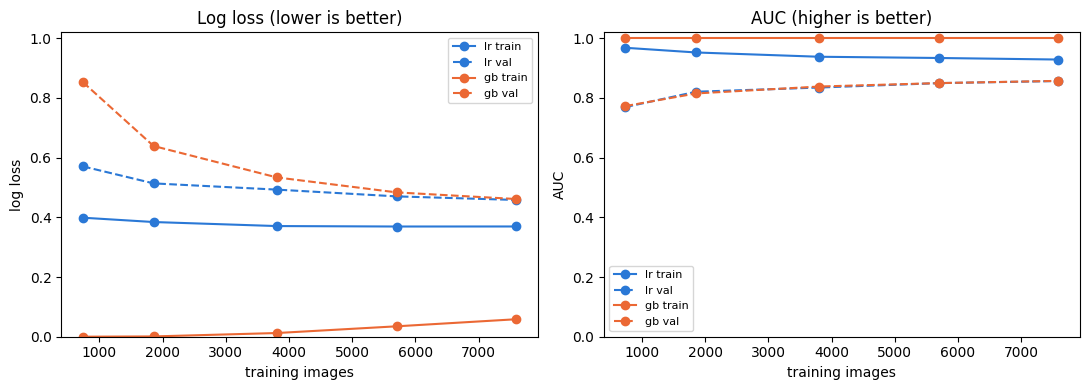

,model,share,train images,train loss,val loss,train AUC,val AUC
0,lr,0.10,738,0.399,0.571,0.968,0.770
1,gb,0.10,738,0.000,0.853,1.000,0.773
2,lr,0.25,1856,0.384,0.514,0.953,0.821
3,gb,0.25,1856,0.001,0.639,1.000,0.815
4,lr,0.50,3806,0.371,0.493,0.938,0.835
5,gb,0.50,3806,0.012,0.534,1.000,0.838
6,lr,0.75,5705,0.369,0.470,0.934,0.850
7,gb,0.75,5705,0.035,0.484,1.000,0.850
8,lr,1.00,7589,0.369,0.458,0.929,0.857
9,gb,1.00,7589,0.059,0.461,1.000,0.857


In [6]:
SHARES = [0.1, 0.25, 0.5, 0.75, 1.0]
curve_file = OUT_DIR / 'learning_curve.csv'

if curve_file.exists():
    curve = pd.read_csv(curve_file)
else:
    rng = np.random.default_rng(42)
    train_patients = np.unique(patient_ids[is_train])
    rng.shuffle(train_patients)

    curve_rows = []
    for share in SHARES:
        n_patients = int(share * len(train_patients))
        chosen = train_patients[:n_patients]
        subset = is_train & np.isin(patient_ids, chosen)

        models = build_models(42)
        for name in models:
            model = models[name]
            model.fit(X[subset], y[subset])
            train_probs = model.predict_proba(X[subset])[:, 1]
            val_probs = model.predict_proba(X[is_val])[:, 1]
            curve_rows.append({'model': name, 'share': share, 'train images': subset.sum(),
                               'train loss': log_loss(y[subset], train_probs),
                               'val loss': log_loss(y[is_val], val_probs),
                               'train AUC': roc_auc_score(y[subset], train_probs),
                               'val AUC': roc_auc_score(y[is_val], val_probs)})
        print(share, 'done')
    curve = pd.DataFrame(curve_rows)
    curve.to_csv(curve_file, index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in MODEL_NAMES:
    rows = curve[curve['model'] == name]
    color = MODEL_COLORS[name]
    axes[0].plot(rows['train images'], rows['train loss'], 'o-', color=color, label=f'{name} train')
    axes[0].plot(rows['train images'], rows['val loss'], 'o--', color=color, label=f'{name} val')
    axes[1].plot(rows['train images'], rows['train AUC'], 'o-', color=color, label=f'{name} train')
    axes[1].plot(rows['train images'], rows['val AUC'], 'o--', color=color, label=f'{name} val')

axes[0].set_title('Log loss (lower is better)')
axes[0].set_xlabel('training images')
axes[0].set_ylabel('log loss')
axes[1].set_title('AUC (higher is better)')
axes[1].set_xlabel('training images')
axes[1].set_ylabel('AUC')
for ax in axes:
    ax.set_ylim(0, 1.02)  # a bit above 1 so the line at 1.0 is not cut off
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

curve.round(3)

## 5. Test results

- threshold: one per model and seed, picked on clean val with Youden's J (max of sensitivity + specificity - 1)
- test groups: full test, clean test, no cast, cast
- numbers: mean ± std over the 3 seeds, and a 95% interval from resampling test patients 1,000 times (bootstrap)

In [7]:
thresholds = {}
for name in MODEL_NAMES:
    for seed in SEEDS:
        val_rows = predictions[(predictions['split'] == 'val') & (predictions['model'] == name) & (predictions['seed'] == seed)]
        fpr, tpr, cutoffs = roc_curve(val_rows['label'], val_rows['prob'])
        best = np.argmax(tpr - fpr)
        thresholds[(name, seed)] = cutoffs[best]
        print(f'threshold {name} seed {seed}: {cutoffs[best]:.3f}')

test = predictions[predictions['split'] == 'test'].copy()
test['predicted'] = 0
for name in MODEL_NAMES:
    for seed in SEEDS:
        rows = (test['model'] == name) & (test['seed'] == seed)
        test.loc[rows, 'predicted'] = (test.loc[rows, 'prob'] >= thresholds[(name, seed)]).astype(int)

GROUPS = ['Full test', 'Clean test', 'No cast', 'Cast']
METRICS = ['AUC', 'sensitivity', 'specificity']


def get_group(part, group):
    if group == 'Full test':
        return part
    elif group == 'Clean test':
        return part[part['clean'] == 1]
    elif group == 'No cast':
        return part[part['cast'] == 0]
    else:
        return part[part['cast'] == 1]


one_model = test[(test['model'] == 'lr') & (test['seed'] == 42)]
print()
for group in GROUPS:
    rows = get_group(one_model, group)
    print(f'{group}: {len(rows)} images, {(rows["label"] == 0).sum()} normal, {100 * rows["label"].mean():.0f}% fracture')

threshold lr seed 42: 0.449
threshold lr seed 1337: 0.449
threshold lr seed 3407: 0.449
threshold gb seed 42: 0.394
threshold gb seed 1337: 0.502
threshold gb seed 3407: 0.496

Full test: 2943 images, 1044 normal, 65% fracture
Clean test: 1637 images, 987 normal, 40% fracture
No cast: 2124 images, 1013 normal, 52% fracture
Cast: 819 images, 31 normal, 96% fracture


In [8]:
def score(part):
    # part = test rows for one model and one seed
    true = part['label'].values
    predicted = part['predicted'].values
    auc = roc_auc_score(true, part['prob'])
    sensitivity = predicted[true == 1].mean()      # fractures found
    specificity = 1 - predicted[true == 0].mean()  # normals called normal
    return {'AUC': auc, 'sensitivity': sensitivity, 'specificity': specificity}


def score_all_seeds(part):
    # mean of each metric over the 3 seeds
    seed_scores = []
    for seed in SEEDS:
        seed_scores.append(score(part[part['seed'] == seed]))
    return pd.DataFrame(seed_scores)


def bootstrap_interval(part, n_resamples=1000):
    # resample patients with replacement, score each resample, return the 2.5% and 97.5% points
    rng = np.random.default_rng(0)
    rows_of_patient = part.groupby('patient_id').indices
    patients = list(rows_of_patient.keys())
    resample_means = []
    for i in range(n_resamples):
        chosen = rng.choice(patients, size=len(patients), replace=True)
        row_numbers = np.concatenate([rows_of_patient[p] for p in chosen])
        resample = part.iloc[row_numbers]
        if resample['label'].nunique() < 2:
            continue  # need both classes for AUC
        resample_means.append(score_all_seeds(resample).mean())
    resample_means = pd.DataFrame(resample_means)
    return resample_means.quantile(0.025), resample_means.quantile(0.975)


results = []
for group in GROUPS:
    for name in MODEL_NAMES:
        part = get_group(test[test['model'] == name], group)
        seed_scores = score_all_seeds(part)
        low, high = bootstrap_interval(part)
        for metric in METRICS:
            results.append({'group': group, 'model': name, 'metric': metric,
                            'mean': seed_scores[metric].mean(), 'std': seed_scores[metric].std(),
                            'low': low[metric], 'high': high[metric]})
results = pd.DataFrame(results)


def get_result(group, name, metric):
    rows = results[(results['group'] == group) & (results['model'] == name) & (results['metric'] == metric)]
    return rows.iloc[0]


print('mean ± std over seeds [bootstrap 95% interval]')
for metric in METRICS:
    print()
    print(metric)
    for group in GROUPS:
        line = f'  {group:<11}'
        for name in MODEL_NAMES:
            r = get_result(group, name, metric)
            line += f'   {name}: {r["mean"]:.3f} ± {r["std"]:.3f} [{r["low"]:.3f}, {r["high"]:.3f}]'
        print(line)

print()
for name in MODEL_NAMES:
    gap = get_result('Full test', name, 'AUC')['mean'] - get_result('Clean test', name, 'AUC')['mean']
    print(f'{name}: full - clean AUC = {gap:.3f}')

mean ± std over seeds [bootstrap 95% interval]

AUC
  Full test     lr: 0.791 ± 0.000 [0.773, 0.810]   gb: 0.871 ± 0.006 [0.856, 0.886]
  Clean test    lr: 0.865 ± 0.000 [0.845, 0.885]   gb: 0.866 ± 0.001 [0.847, 0.886]
  No cast       lr: 0.862 ± 0.000 [0.844, 0.882]   gb: 0.863 ± 0.003 [0.844, 0.882]
  Cast          lr: 0.589 ± 0.000 [0.439, 0.728]   gb: 0.645 ± 0.004 [0.576, 0.722]

sensitivity
  Full test     lr: 0.653 ± 0.000 [0.628, 0.679]   gb: 0.709 ± 0.032 [0.682, 0.732]
  Clean test    lr: 0.714 ± 0.000 [0.674, 0.752]   gb: 0.694 ± 0.041 [0.654, 0.731]
  No cast       lr: 0.732 ± 0.000 [0.701, 0.763]   gb: 0.694 ± 0.039 [0.664, 0.726]
  Cast          lr: 0.542 ± 0.000 [0.507, 0.577]   gb: 0.729 ± 0.025 [0.699, 0.760]

specificity
  Full test     lr: 0.823 ± 0.000 [0.798, 0.846]   gb: 0.858 ± 0.039 [0.836, 0.878]
  Clean test    lr: 0.831 ± 0.000 [0.804, 0.856]   gb: 0.876 ± 0.040 [0.856, 0.897]
  No cast       lr: 0.828 ± 0.000 [0.804, 0.854]   gb: 0.873 ± 0.040 [0.855, 0.893

### Metrics by group

Bar = mean over seeds, line = bootstrap 95% interval.

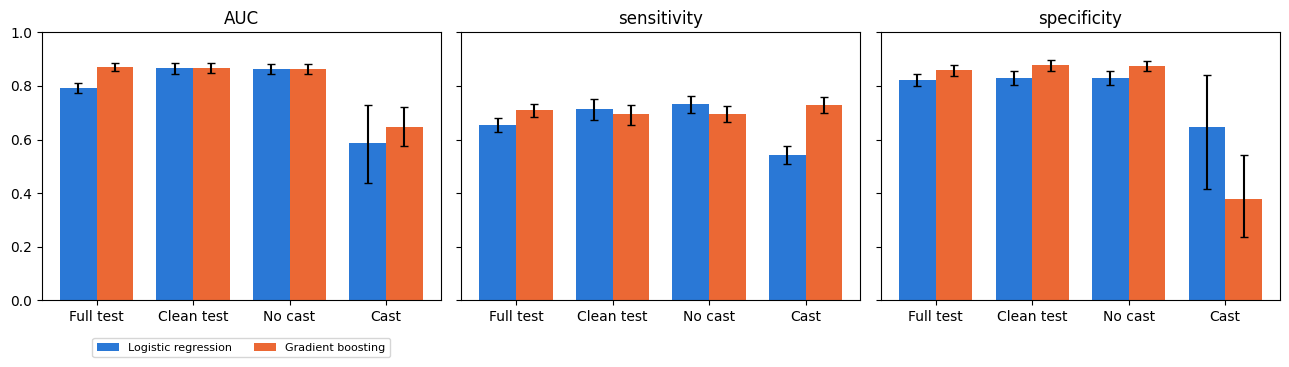

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
x = np.arange(len(GROUPS))
width = 0.38

for i in range(len(METRICS)):
    metric = METRICS[i]
    ax = axes[i]
    for k, name in enumerate(MODEL_NAMES):
        means = []
        below = []
        above = []
        for group in GROUPS:
            r = get_result(group, name, metric)
            means.append(r['mean'])
            below.append(r['mean'] - r['low'])
            above.append(r['high'] - r['mean'])
        ax.bar(x + (k - 0.5) * width, means, width=width, yerr=[below, above], capsize=3,
               color=MODEL_COLORS[name], label=MODEL_NAMES[name])
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_title(metric)
    ax.set_ylim(0, 1)

axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

### ROC curves

Curves use the probability averaged over the 3 seeds. AUC in the legend is the mean over seeds (same as the table).

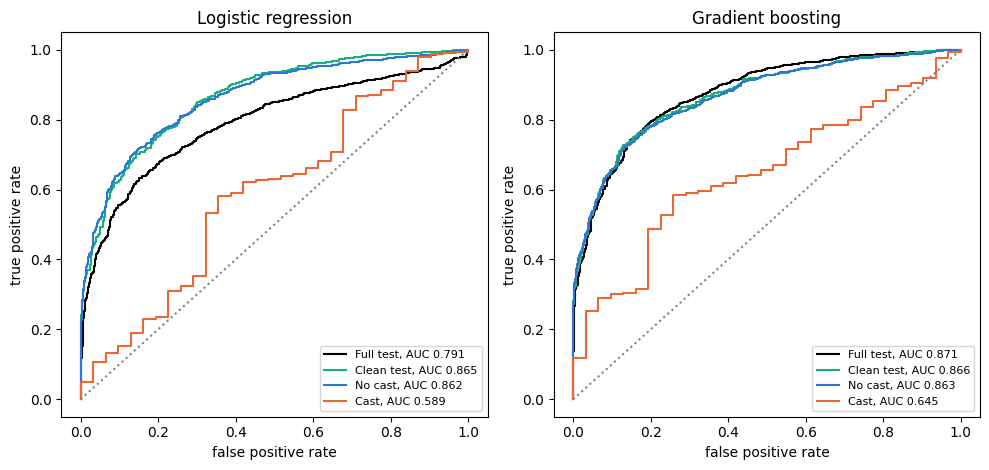

In [10]:
# rows of each model and seed are in the same image order, so the seeds can be averaged directly
mean_probs = {}
for name in MODEL_NAMES:
    seed_probs = []
    for seed in SEEDS:
        seed_probs.append(test[(test['model'] == name) & (test['seed'] == seed)]['prob'].values)
    mean_probs[name] = np.mean(seed_probs, axis=0)

images = test[(test['model'] == 'lr') & (test['seed'] == 42)].copy()  # one row per test image
group_colors = {'Full test': 'black', 'Clean test': '#1baf7a', 'No cast': '#2a78d6', 'Cast': '#eb6834'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, name in zip(axes, MODEL_NAMES):
    images['mean_prob'] = mean_probs[name]
    for group in GROUPS:
        rows = get_group(images, group)
        fpr, tpr, _ = roc_curve(rows['label'], rows['mean_prob'])
        auc = get_result(group, name, 'AUC')['mean']
        ax.plot(fpr, tpr, color=group_colors[group], label=f'{group}, AUC {auc:.3f}')
    ax.plot([0, 1], [0, 1], color='grey', linestyle=':')
    ax.set_title(MODEL_NAMES[name])
    ax.set_xlabel('false positive rate')
    ax.set_ylabel('true positive rate')
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

### Predicted probabilities

Mean probability over seeds for normal and fracture images, with and without a cast. Dashed line = mean threshold.
The models never saw a cast in training, so the right column shows what they do with one.

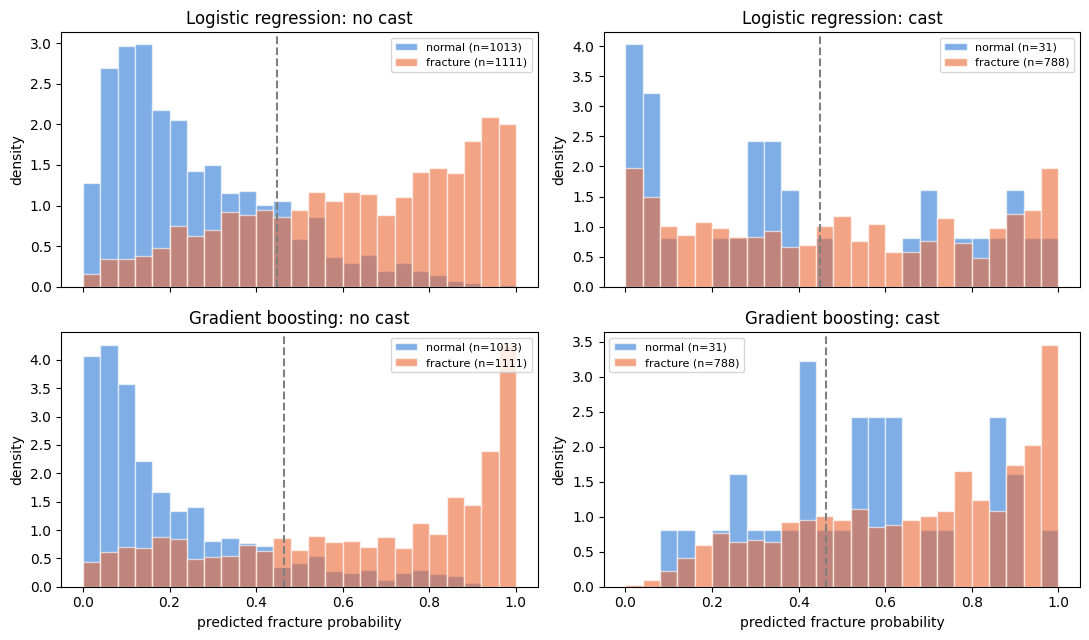

In [11]:
bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)

for row, name in enumerate(MODEL_NAMES):
    images['mean_prob'] = mean_probs[name]
    mean_threshold = np.mean([thresholds[(name, seed)] for seed in SEEDS])
    for col, cast_value in enumerate([0, 1]):
        ax = axes[row, col]
        cast_rows = images[images['cast'] == cast_value]
        normal_probs = cast_rows[cast_rows['label'] == 0]['mean_prob']
        fracture_probs = cast_rows[cast_rows['label'] == 1]['mean_prob']
        ax.hist(normal_probs, bins=bins, density=True, alpha=0.6, color='#2a78d6', edgecolor='white', label=f'normal (n={len(normal_probs)})')
        ax.hist(fracture_probs, bins=bins, density=True, alpha=0.6, color='#eb6834', edgecolor='white', label=f'fracture (n={len(fracture_probs)})')
        ax.axvline(mean_threshold, color='grey', linestyle='--')
        if cast_value == 1:
            ax.set_title(f'{MODEL_NAMES[name]}: cast')
        else:
            ax.set_title(f'{MODEL_NAMES[name]}: no cast')
        ax.set_ylabel('density')
        ax.legend(fontsize=8)

axes[1, 0].set_xlabel('predicted fracture probability')
axes[1, 1].set_xlabel('predicted fracture probability')
plt.tight_layout()
plt.show()

### Confusion matrices

Each row adds up to 100% (share of the true class). The small number is the image count, averaged over the 3 seeds.

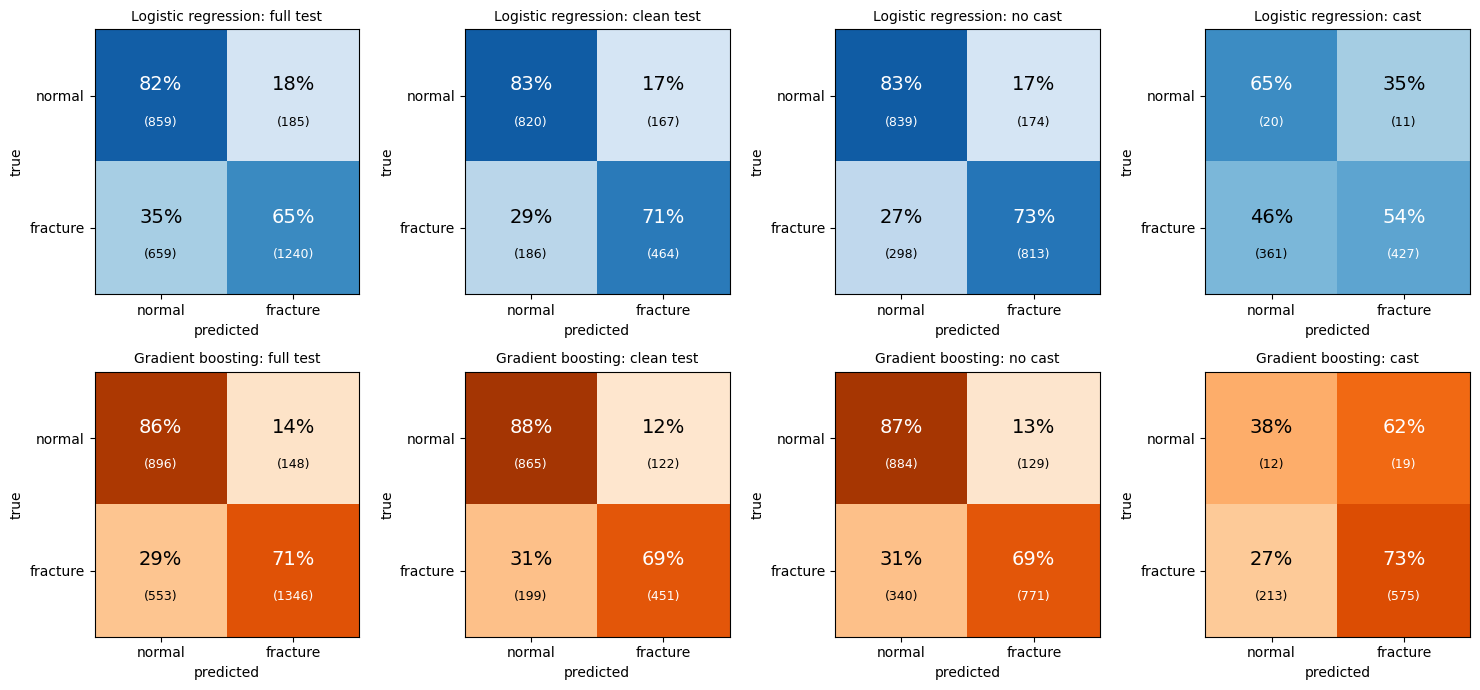

In [12]:
cmaps = {'lr': 'Blues', 'gb': 'Oranges'}
fig, axes = plt.subplots(2, 4, figsize=(15, 7))

for row, name in enumerate(MODEL_NAMES):
    for col, group in enumerate(GROUPS):
        ax = axes[row, col]
        rows = get_group(test[test['model'] == name], group)

        # count over all 3 seeds, then divide by 3
        matrix = np.zeros((2, 2))
        for true_value in [0, 1]:
            for pred_value in [0, 1]:
                matrix[true_value, pred_value] = ((rows['label'] == true_value) & (rows['predicted'] == pred_value)).sum() / 3

        row_share = matrix / matrix.sum(axis=1, keepdims=True)
        ax.imshow(row_share, cmap=cmaps[name], vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                if row_share[i, j] > 0.5:
                    text_color = 'white'
                else:
                    text_color = 'black'
                ax.text(j, i - 0.08, f'{row_share[i, j]:.0%}', ha='center', va='center', color=text_color, fontsize=14)
                ax.text(j, i + 0.2, f'({matrix[i, j]:.0f})', ha='center', va='center', color=text_color, fontsize=9)

        ax.set_xticks([0, 1])
        ax.set_xticklabels(['normal', 'fracture'])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(['normal', 'fracture'])
        ax.set_xlabel('predicted')
        ax.set_ylabel('true')
        ax.set_title(f'{MODEL_NAMES[name]}: {group.lower()}', fontsize=10)

plt.tight_layout()
plt.show()

## 6. Findings

Mean ± std over 3 seeds, bootstrap 95% interval in brackets.

- CV AUC is 0.857-0.861 for LR and 0.855-0.858 for GB. Val AUC is about the same (0.855-0.862), so the models do as well on new patients.
- LR gives the same model for every seed (std 0). GB seeds change AUC very little (± 0.001 on clean test) but sensitivity and specificity more (± 0.04), since each seed has its own threshold.
- Clean test AUC: LR 0.865 [0.845, 0.885], GB 0.866 ± 0.001 [0.847, 0.886].
- Full test AUC is not higher than clean test (LR 0.791, GB 0.871). The models never saw a cast, so they can't use it as a shortcut.
- Casts: LR calls 65% of the normal casts normal, GB only 38%. Cast AUC is low (LR 0.59, GB 0.65) and LR only finds about half the fractures under a cast (sensitivity 0.54). The cast covers the bone and these images look nothing like the training images. There are only 31 normal cast images, so these intervals are wide.
- LR full test AUC (0.791) is low for the same reason: a lot of fractures in a cast get a low score.
- Learning curve: val loss keeps going down and val AUC keeps going up all the way to 100% of the data (AUC 0.77 to 0.857), so more clean images would probably still help. GB fits its training images almost perfectly (train AUC 1.0, train loss near 0), so it overfits a lot, but the gap gets smaller with more data. LR's gap is smaller (val minus train loss goes from 0.17 to 0.09).